# Model Training, Benchmarking & Evaluation — Olist Delivery Time Prediction

Notebook này thực hiện:
1. Đọc dữ liệu đã tiền xử lý từ `processed/` (`train.csv`, `val.csv`, `test.csv`).
2. Đánh giá 2 **Baselines**: `Baseline_Median` và `Baseline_Olist_Estimated`.
3. Huấn luyện & so sánh các mô hình: `Ridge_Regression`, `Random_Forest`, `XGBoost`, `LightGBM_L2`, `LightGBM_L1`.
4. Lưu mô hình tốt nhất vào `model/best_model.pkl`, bảng so sánh vào `model/model_comparison.csv` và các biểu đồ đánh giá vào `model_figures/`.

In [1]:
import json
import os
import pickle
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler
import lightgbm as lgb
import xgboost as xgb

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')
plt.rcParams['figure.dpi'] = 120

PROC_DIR = 'processed'
MODEL_DIR = 'model'
FIG_DIR = 'model_figures'
os.makedirs(MODEL_DIR, exist_ok=True)
os.makedirs(FIG_DIR, exist_ok=True)

## 1. Load dữ liệu & Định nghĩa hàm đánh giá

In [2]:
with open(os.path.join(PROC_DIR, 'feature_metadata.json'), 'r', encoding='utf-8') as f:
    meta = json.load(f)

target_col = meta['target_col']
bench_col = meta['benchmark_col']
num_features = meta['num_features']
cat_features = meta['cat_features']
all_features = num_features + cat_features

train_df = pd.read_csv(os.path.join(PROC_DIR, 'train.csv'))
val_df = pd.read_csv(os.path.join(PROC_DIR, 'val.csv'))
test_df = pd.read_csv(os.path.join(PROC_DIR, 'test.csv'))

X_train, y_train = train_df[all_features], train_df[target_col].values
X_val, y_val = val_df[all_features], val_df[target_col].values
X_test, y_test = test_df[all_features], test_df[target_col].values

def eval_metrics(y_true, y_pred):
    err = np.abs(y_true - y_pred)
    return {
        'MAE': float(mean_absolute_error(y_true, y_pred)),
        'RMSE': float(np.sqrt(mean_squared_error(y_true, y_pred))),
        'R2': float(r2_score(y_true, y_pred)),
        'Within_3d_%': float((err <= 3.0).mean() * 100.0),
        'Within_5d_%': float((err <= 5.0).mean() * 100.0),
    }

records = []
def log_result(name, val_pred, test_pred):
    vm = eval_metrics(y_val, val_pred)
    tm = eval_metrics(y_test, test_pred)
    records.append({
        'Model': name,
        'Val_MAE': vm['MAE'],
        'Val_RMSE': vm['RMSE'],
        'Test_MAE': tm['MAE'],
        'Test_RMSE': tm['RMSE'],
        'Test_R2': tm['R2'],
        'Test_Within_3d_%': tm['Within_3d_%'],
        'Test_Within_5d_%': tm['Within_5d_%'],
    })
    print(f"[{name}] Val MAE={vm['MAE']:.3f} | Test MAE={tm['MAE']:.3f} | Test RMSE={tm['RMSE']:.3f} | R2={tm['R2']:.3f} | ±3d={tm['Within_3d_%']:.1f}%")

print(f'Loaded Train={len(train_df):,}, Val={len(val_df):,}, Test={len(test_df):,}')

Loaded Train=67,529, Val=14,470, Test=14,471


## 2. Đánh giá Baselines & Ridge Regression

In [3]:
# 1. Baselines
train_median = float(np.median(y_train))
log_result('Baseline_Median', np.full_like(y_val, train_median), np.full_like(y_test, train_median))
log_result('Baseline_Olist_Estimated', val_df[bench_col].values, test_df[bench_col].values)

# 2. Ridge Regression
ridge_pipe = Pipeline([
    ('prep', ColumnTransformer([
        ('num', StandardScaler(), num_features),
        ('cat', OneHotEncoder(handle_unknown='ignore'), cat_features),
    ])),
    ('model', Ridge(alpha=10.0, random_state=42)),
])
ridge_pipe.fit(X_train, y_train)
log_result('Ridge_Regression', ridge_pipe.predict(X_val), ridge_pipe.predict(X_test))

[Baseline_Median] Val MAE=5.694 | Test MAE=5.087 | Test RMSE=6.284 | R2=-0.324 | ±3d=27.7%
[Baseline_Olist_Estimated] Val MAE=14.910 | Test MAE=10.722 | Test RMSE=13.112 | R2=-4.764 | ±3d=14.1%
[Ridge_Regression] Val MAE=4.739 | Test MAE=4.039 | Test RMSE=5.528 | R2=-0.025 | ±3d=48.0%


## 3. Huấn luyện các mô hình Tree-based (Random Forest, XGBoost, LightGBM)

In [4]:
tree_prep = ColumnTransformer([
    ('num', 'passthrough', num_features),
    ('cat', OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1), cat_features),
])
X_train_t = tree_prep.fit_transform(X_train)
X_val_t = tree_prep.transform(X_val)
X_test_t = tree_prep.transform(X_test)
feat_names_t = num_features + cat_features

# 3. Random Forest
rf = RandomForestRegressor(n_estimators=150, max_depth=14, min_samples_leaf=10, n_jobs=-1, random_state=42)
rf.fit(X_train_t, y_train)
log_result('Random_Forest', rf.predict(X_val_t), rf.predict(X_test_t))

# 4. XGBoost
xgb_model = xgb.XGBRegressor(
    n_estimators=1000, learning_rate=0.05, max_depth=6,
    subsample=0.8, colsample_bytree=0.8, early_stopping_rounds=50,
    eval_metric='mae', n_jobs=-1, random_state=42,
)
xgb_model.fit(X_train_t, y_train, eval_set=[(X_val_t, y_val)], verbose=False)
log_result('XGBoost', xgb_model.predict(X_val_t), xgb_model.predict(X_test_t))

# 5. LightGBM (L2 vs L1/MAE)
lgb_l2 = lgb.LGBMRegressor(
    objective='regression', n_estimators=1200, learning_rate=0.04, num_leaves=63,
    subsample_for_bin=50000, colsample_bytree=0.8, subsample=0.8,
    min_child_samples=30, random_state=42, n_jobs=-1, verbose=-1,
)
lgb_l2.fit(X_train_t, y_train, eval_set=[(X_val_t, y_val)], callbacks=[lgb.early_stopping(50, verbose=False)])
log_result('LightGBM_L2', lgb_l2.predict(X_val_t), lgb_l2.predict(X_test_t))

lgb_l1 = lgb.LGBMRegressor(
    objective='regression_l1', n_estimators=1200, learning_rate=0.04, num_leaves=63,
    colsample_bytree=0.8, subsample=0.8, min_child_samples=30,
    random_state=42, n_jobs=-1, verbose=-1,
)
lgb_l1.fit(X_train_t, y_train, eval_set=[(X_val_t, y_val)], callbacks=[lgb.early_stopping(50, verbose=False)])
log_result('LightGBM_L1', lgb_l1.predict(X_val_t), lgb_l1.predict(X_test_t))

[Random_Forest] Val MAE=4.542 | Test MAE=4.464 | Test RMSE=5.708 | R2=-0.092 | ±3d=37.3%
[XGBoost] Val MAE=4.496 | Test MAE=4.156 | Test RMSE=5.427 | R2=0.013 | ±3d=41.6%
[LightGBM_L2] Val MAE=4.470 | Test MAE=4.210 | Test RMSE=5.424 | R2=0.014 | ±3d=40.0%
[LightGBM_L1] Val MAE=4.040 | Test MAE=3.474 | Test RMSE=4.854 | R2=0.210 | ±3d=53.3%


## 4. Hyperparameter Tuning (LightGBM L1 & XGBoost L1 trên tập Validation)

In [5]:
rng = np.random.RandomState(42)
tuning_logs = []

# --- 4.1 Tune LightGBM (L1 / MAE) ---
lgb_grid = {
    'num_leaves': [31, 63, 95, 127],
    'min_child_samples': [20, 30, 50, 80],
    'learning_rate': [0.02, 0.03, 0.05],
    'colsample_bytree': [0.6, 0.7, 0.8, 0.9],
    'subsample': [0.7, 0.8, 0.9],
    'reg_alpha': [0.0, 0.1, 1.0, 5.0],
    'reg_lambda': [0.0, 1.0, 5.0, 10.0],
}

best_lgb_val_mae = float('inf')
best_lgb_model = None
best_lgb_params = None

for trial in range(12):
    params = {k: rng.choice(v).item() for k, v in lgb_grid.items()}
    model = lgb.LGBMRegressor(
        objective='regression_l1', n_estimators=1500, subsample_freq=1,
        random_state=42, n_jobs=-1, verbose=-1, **params
    )
    model.fit(X_train_t, y_train, eval_set=[(X_val_t, y_val)], callbacks=[lgb.early_stopping(50, verbose=False)])
    val_mae = mean_absolute_error(y_val, model.predict(X_val_t))
    tuning_logs.append({'Family': 'LightGBM_L1', 'Trial': trial + 1, 'Val_MAE': val_mae, **params})
    if val_mae < best_lgb_val_mae:
        best_lgb_val_mae = val_mae
        best_lgb_model = model
        best_lgb_params = params

print(f'Best LightGBM_L1_Tuned Val MAE={best_lgb_val_mae:.4f} | Params={best_lgb_params}')
log_result('LightGBM_L1_Tuned', best_lgb_model.predict(X_val_t), best_lgb_model.predict(X_test_t))

# --- 4.2 Tune XGBoost (L1 / reg:absoluteerror) ---
xgb_grid = {
    'max_depth': [5, 6, 8],
    'learning_rate': [0.03, 0.05],
    'min_child_weight': [5, 15, 30],
    'subsample': [0.7, 0.8],
    'colsample_bytree': [0.7, 0.8],
    'reg_alpha': [0.0, 1.0],
    'reg_lambda': [1.0, 5.0],
}

best_xgb_val_mae = float('inf')
best_xgb_model = None
best_xgb_params = None

for trial in range(8):
    params = {k: rng.choice(v).item() for k, v in xgb_grid.items()}
    model = xgb.XGBRegressor(
        objective='reg:absoluteerror', n_estimators=1200, early_stopping_rounds=50,
        eval_metric='mae', n_jobs=-1, random_state=42, **params
    )
    model.fit(X_train_t, y_train, eval_set=[(X_val_t, y_val)], verbose=False)
    val_mae = mean_absolute_error(y_val, model.predict(X_val_t))
    tuning_logs.append({'Family': 'XGBoost_L1', 'Trial': trial + 1, 'Val_MAE': val_mae, **params})
    if val_mae < best_xgb_val_mae:
        best_xgb_val_mae = val_mae
        best_xgb_model = model
        best_xgb_params = params

print(f'Best XGBoost_L1_Tuned Val MAE={best_xgb_val_mae:.4f} | Params={best_xgb_params}')
log_result('XGBoost_L1_Tuned', best_xgb_model.predict(X_val_t), best_xgb_model.predict(X_test_t))

tuning_df = pd.DataFrame(tuning_logs).sort_values('Val_MAE')
tuning_df.to_csv(os.path.join(MODEL_DIR, 'tuning_results.csv'), index=False)
tuning_df.head(10)

Best LightGBM_L1_Tuned Val MAE=4.0163 | Params={'num_leaves': 31, 'min_child_samples': 50, 'learning_rate': 0.03, 'colsample_bytree': 0.8, 'subsample': 0.9, 'reg_alpha': 1.0, 'reg_lambda': 5.0}
[LightGBM_L1_Tuned] Val MAE=4.016 | Test MAE=3.469 | Test RMSE=4.846 | R2=0.213 | ±3d=53.4%
Best XGBoost_L1_Tuned Val MAE=4.0032 | Params={'max_depth': 6, 'learning_rate': 0.03, 'min_child_weight': 30, 'subsample': 0.8, 'colsample_bytree': 0.8, 'reg_alpha': 1.0, 'reg_lambda': 5.0}
[XGBoost_L1_Tuned] Val MAE=4.003 | Test MAE=3.404 | Test RMSE=4.805 | R2=0.226 | ±3d=54.6%


,Family,Trial,Val_MAE,num_leaves,min_child_samples,learning_rate,colsample_bytree,subsample,reg_alpha,reg_lambda,max_depth,min_child_weight
12,XGBoost_L1,1,4.003179,NaN,NaN,0.03,0.8,0.8,1.0,5.0,6.0,30.0
16,XGBoost_L1,5,4.004264,NaN,NaN,0.03,0.7,0.7,0.0,1.0,5.0,5.0
15,XGBoost_L1,4,4.014198,NaN,NaN,0.05,0.8,0.7,1.0,1.0,5.0,30.0
1,LightGBM_L1,2,4.016270,31.0,50.0,0.03,0.8,0.9,1.0,5.0,NaN,NaN
14,XGBoost_L1,3,4.016812,NaN,NaN,0.03,0.8,0.8,0.0,5.0,6.0,5.0
9,LightGBM_L1,10,4.017692,31.0,30.0,0.02,0.7,0.9,5.0,5.0,NaN,NaN
11,LightGBM_L1,12,4.020696,63.0,80.0,0.03,0.7,0.8,0.1,1.0,NaN,NaN
13,XGBoost_L1,2,4.022534,NaN,NaN,0.05,0.8,0.7,0.0,5.0,6.0,15.0
7,LightGBM_L1,8,4.026475,31.0,50.0,0.02,0.8,0.9,0.0,0.0,NaN,NaN
19,XGBoost_L1,8,4.033115,NaN,NaN,0.03,0.8,0.7,0.0,5.0,8.0,15.0


## 5. Tổng hợp kết quả, Lưu Best Model & Vẽ biểu đồ phân tích

In [6]:
results_df = pd.DataFrame(records).sort_values('Test_MAE')
results_df.to_csv(os.path.join(MODEL_DIR, 'model_comparison.csv'), index=False)

ml_models = {
    'Ridge_Regression': (ridge_pipe, ridge_pipe.predict(X_test), None),
    'Random_Forest': (Pipeline([('prep', tree_prep), ('model', rf)]), rf.predict(X_test_t), rf.feature_importances_),
    'XGBoost': (Pipeline([('prep', tree_prep), ('model', xgb_model)]), xgb_model.predict(X_test_t), xgb_model.feature_importances_),
    'LightGBM_L2': (Pipeline([('prep', tree_prep), ('model', lgb_l2)]), lgb_l2.predict(X_test_t), lgb_l2.feature_importances_),
    'LightGBM_L1': (Pipeline([('prep', tree_prep), ('model', lgb_l1)]), lgb_l1.predict(X_test_t), lgb_l1.feature_importances_),
    'LightGBM_L1_Tuned': (Pipeline([('prep', tree_prep), ('model', best_lgb_model)]), best_lgb_model.predict(X_test_t), best_lgb_model.feature_importances_),
    'XGBoost_L1_Tuned': (Pipeline([('prep', tree_prep), ('model', best_xgb_model)]), best_xgb_model.predict(X_test_t), best_xgb_model.feature_importances_),
}

ml_rows = results_df[results_df['Model'].isin(ml_models.keys())]
best_name = ml_rows.sort_values('Val_MAE').iloc[0]['Model']
best_pipe, best_test_pred, best_importances = ml_models[best_name]

with open(os.path.join(MODEL_DIR, 'best_model.pkl'), 'wb') as f:
    pickle.dump(best_pipe, f)

print(f'Best model (by Val MAE): {best_name}')
results_df

Best model (by Val MAE): XGBoost_L1_Tuned


,Model,Val_MAE,Val_RMSE,Test_MAE,Test_RMSE,Test_R2,Test_Within_3d_%,Test_Within_5d_%
8,XGBoost_L1_Tuned,4.003179,6.165593,3.403983,4.804536,0.226094,54.591943,78.805888
7,LightGBM_L1_Tuned,4.016270,6.164623,3.469258,4.845506,0.212839,53.444821,78.301430
6,LightGBM_L1,4.039752,6.180179,3.474026,4.854489,0.209917,53.258241,77.838435
2,Ridge_Regression,4.738894,6.528977,4.038720,5.527996,-0.024521,47.978716,69.829314
4,XGBoost,4.496483,6.338343,4.156285,5.426912,0.012605,41.621173,69.400871
5,LightGBM_L2,4.469514,6.293964,4.209648,5.424302,0.013554,39.962684,68.371225
3,Random_Forest,4.542303,6.355135,4.463557,5.707848,-0.092271,37.295280,64.964412
0,Baseline_Median,5.693889,7.741468,5.086576,6.283504,-0.323699,27.717504,52.069657
1,Baseline_Olist_Estimated,14.910214,17.266384,10.722452,13.112371,-4.764318,14.055698,23.004630


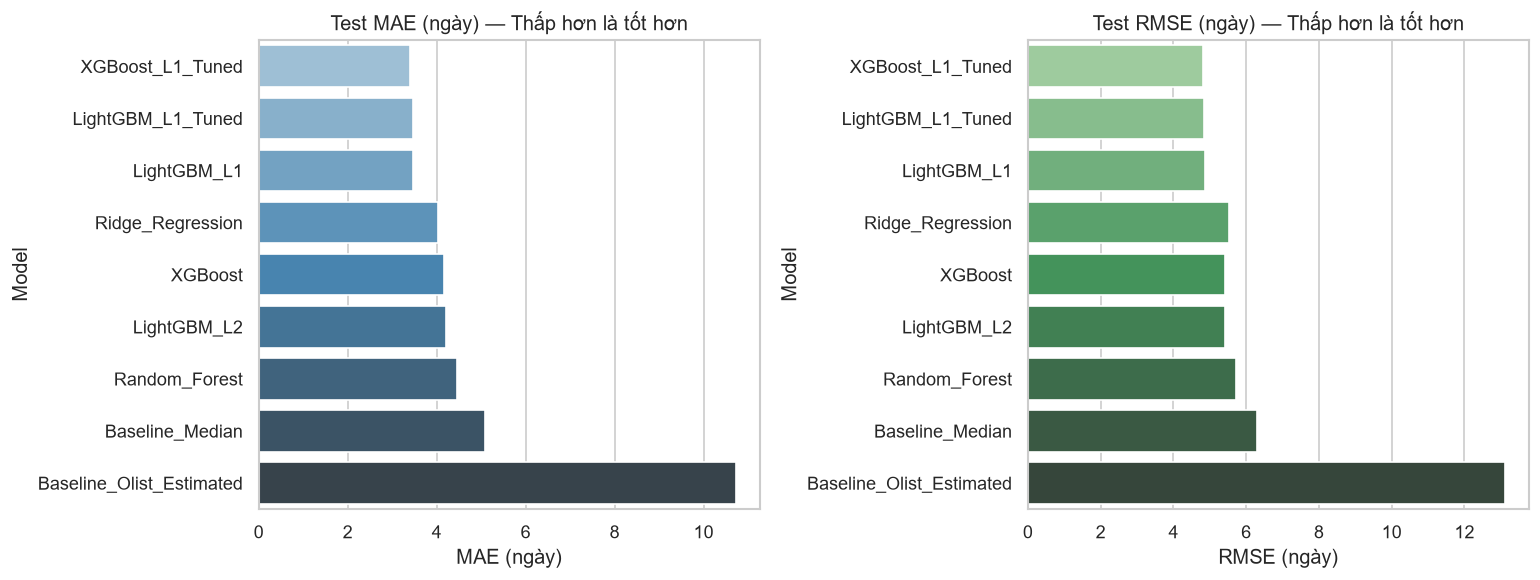

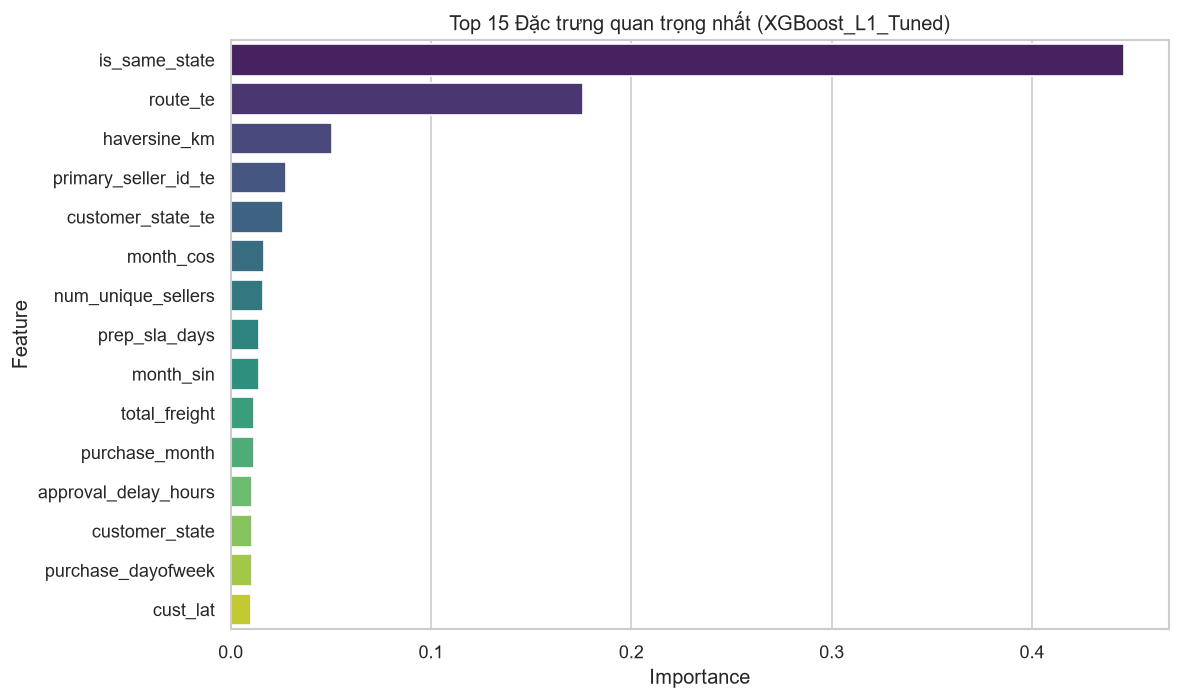

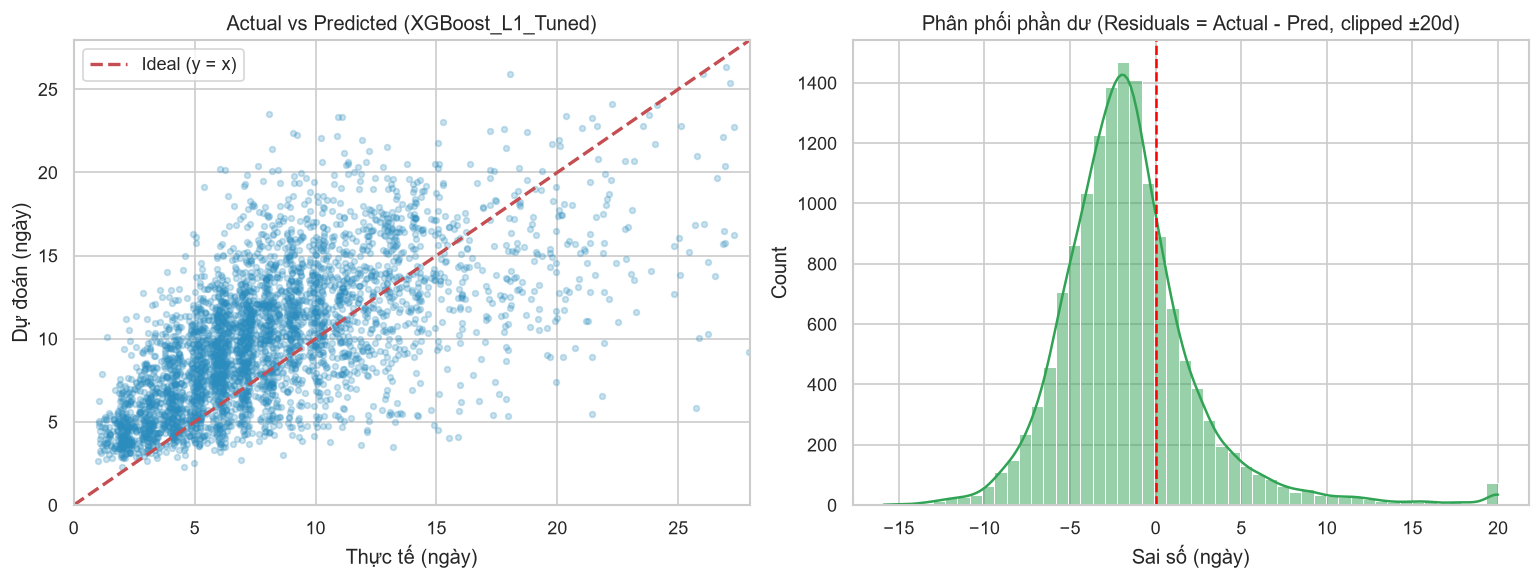

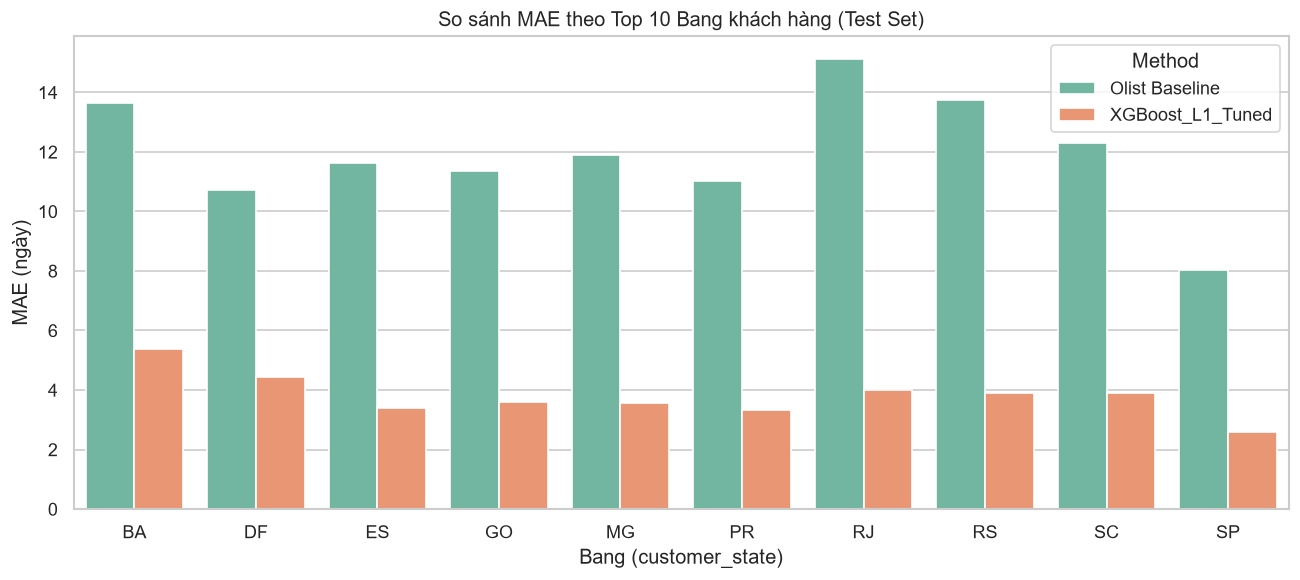

In [7]:
# 1. Model Comparison
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
plot_df = results_df.sort_values('Test_MAE')
sns.barplot(data=plot_df, x='Test_MAE', y='Model', ax=axes[0], palette='Blues_d')
axes[0].set_title('Test MAE (ngày) — Thấp hơn là tốt hơn')
axes[0].set_xlabel('MAE (ngày)')

sns.barplot(data=plot_df, x='Test_RMSE', y='Model', ax=axes[1], palette='Greens_d')
axes[1].set_title('Test RMSE (ngày) — Thấp hơn là tốt hơn')
axes[1].set_xlabel('RMSE (ngày)')
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, '01_model_comparison.png'), bbox_inches='tight')
plt.show()

# 2. Feature Importance
if best_importances is not None:
    imp_df = pd.DataFrame({'Feature': feat_names_t, 'Importance': best_importances}).sort_values('Importance', ascending=False).head(15)
    plt.figure(figsize=(10, 6))
    sns.barplot(data=imp_df, x='Importance', y='Feature', palette='viridis')
    plt.title(f'Top 15 Đặc trưng quan trọng nhất ({best_name})')
    plt.tight_layout()
    plt.savefig(os.path.join(FIG_DIR, '02_feature_importance.png'), bbox_inches='tight')
    plt.show()

# 3. Actual vs Predicted & Residuals
residuals = y_test - best_test_pred
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sample_idx = np.random.RandomState(42).choice(len(y_test), size=min(4000, len(y_test)), replace=False)
axes[0].scatter(y_test[sample_idx], best_test_pred[sample_idx], alpha=0.25, s=12, color='#2b8cbe')
max_val = min(45, float(np.percentile(y_test, 99)))
axes[0].plot([0, max_val], [0, max_val], 'r--', lw=2, label='Ideal (y = x)')
axes[0].set_xlim(0, max_val)
axes[0].set_ylim(0, max_val)
axes[0].set_title(f'Actual vs Predicted ({best_name})')
axes[0].set_xlabel('Thực tế (ngày)')
axes[0].set_ylabel('Dự đoán (ngày)')
axes[0].legend()

sns.histplot(np.clip(residuals, -20, 20), bins=50, kde=True, ax=axes[1], color='#31a354')
axes[1].axvline(0, color='red', linestyle='--')
axes[1].set_title('Phân phối phần dư (Residuals = Actual - Pred, clipped ±20d)')
axes[1].set_xlabel('Sai số (ngày)')
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, '03_actual_vs_predicted.png'), bbox_inches='tight')
plt.show()

# 4. Error by State
err_df = pd.DataFrame({
    'state': test_df['customer_state'].values,
    'olist_err': np.abs(y_test - test_df['olist_estimated_days'].values),
    'ml_err': np.abs(y_test - best_test_pred),
})
top_states = err_df['state'].value_counts().head(10).index
state_cmp = (
    err_df[err_df['state'].isin(top_states)]
    .groupby('state')[['olist_err', 'ml_err']]
    .mean().reset_index()
    .melt(id_vars='state', var_name='Method', value_name='MAE')
)
state_cmp['Method'] = state_cmp['Method'].map({'olist_err': 'Olist Baseline', 'ml_err': best_name})
plt.figure(figsize=(11, 5))
sns.barplot(data=state_cmp, x='state', y='MAE', hue='Method', palette='Set2')
plt.title('So sánh MAE theo Top 10 Bang khách hàng (Test Set)')
plt.xlabel('Bang (customer_state)')
plt.ylabel('MAE (ngày)')
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, '04_error_by_state.png'), bbox_inches='tight')
plt.show()